# Standard NicheNet Workflow: From GRN to ccflowR Visualization

## Biological Question

Here we ask: **which sender-cell ligands are associated with basal epithelial gene-expression changes between contralateral (C) and normal adjacent (N) tissue?** This is a condition-comparison problem: the receiver cell type is fixed to basal epithelium, and the contrast is C vs N within those basal cells.

This tutorial is the main single-contrast workflow. It links four layers of interpretation:

1. **Differential receiver program**: genes that distinguish C from N basal cells.
2. **Ligand activity**: ligands whose predicted targets recover that receiver program.
3. **Ligand-target mechanisms**: target genes that connect top ligands to the receiver response.
4. **ccflowR Sankey view**: sender -> ligand -> receptor -> target -> receiver paths that make the communication hypothesis inspectable.

## Learning Objectives

By the end of this tutorial, you will be able to:

- Run the complete ContextNet -> NicheNet pipeline with condition comparison mode
- Interpret ligand activity scores and ligand-target regulatory potential
- Inspect `ContextGRN`, `ContextNetwork`, and `ContextResult` objects
- Extract matrices and tables for downstream analyses
- Render cell-cell communication as a Sankey diagram with ccflowR
- Save and reload ContextNet objects for reproducibility

## Overview

We study **signaling to basal epithelial cells** comparing contralateral (C) vs normal adjacent (N) tissue. This demonstrates **condition comparison mode** (`de_subset_receiver = TRUE`), which identifies ligands whose targets are differentially expressed between conditions within the receiver cell type.

This contrasts with Tutorial 01, which uses **cell type comparison** (`de_subset_receiver = FALSE`) to find basal-specific genes relative to other epithelial layers.

> **When to use this workflow:**
> - You have two conditions, such as disease/control or treated/untreated.
> - You want an interpretable single receiver-cell analysis.
> - You do not have biological replicates, or you intentionally want the simpler Wilcoxon-based workflow.
>
> **Use [03-multicondition-workflow](03-multicondition-workflow.ipynb) instead if:**
> - You have biological replicates and want pseudobulk, replicate-aware differential communication.

## Setup

In [ ]:
suppressPackageStartupMessages({
    library(ContextNet)
    library(Seurat)
    library(nichenetr)
    library(dplyr)
    library(ggplot2)
})

theme_set(theme_minimal(base_family = "sans"))


In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║                    USER CONFIGURATION                       ║
# ║  Paths are relative to the ContextNet project root.          ║
# ╚══════════════════════════════════════════════════════════════╝

PROJECT_DIR <- normalizePath(getwd(), mustWork = TRUE)
if (basename(PROJECT_DIR) == "notebooks" &&
    file.exists(file.path(PROJECT_DIR, "..", "DESCRIPTION"))) {
    PROJECT_DIR <- normalizePath(file.path(PROJECT_DIR, ".."), mustWork = TRUE)
}
if (!file.exists(file.path(PROJECT_DIR, "DESCRIPTION"))) {
    stop("Run this notebook from the ContextNet repository root or from the notebooks/ directory.")
}
setwd(PROJECT_DIR)
cat("Working directory:", getwd(), "
")

DATA_PATH       <- "data"
GRN_FILE        <- file.path(DATA_PATH, "gene_x_tf.csv")
SEURAT_FILE     <- file.path(DATA_PATH, "seurat_obj.rds")
NICHENET_DB     <- DATA_PATH

# Analysis parameters: condition comparison for basal cells
SENDER          <- NULL           # Auto-detect: all cell types with >500 cells
RECEIVER        <- "basal"
GROUP_COL       <- "Fine_Cell_Types"
IDENT_COL       <- "category"     # Condition column (C vs N)
IDENT_1         <- "C"            # Contralateral (condition of interest)
IDENT_2         <- "N"            # Normal adjacent (reference)
MIN_CELLS       <- 500            # Minimum cells for sender cell types
TOP_N_LIGANDS   <- 30

stopifnot(file.exists(GRN_FILE), file.exists(SEURAT_FILE))


## Step 1: Import GRN

The context-specific GRN is a gene × TF matrix (CSV) where rows are target genes, columns are transcription factors, and values are regulatory weights inferred from matched scRNA-seq + scATAC-seq data.

In [3]:
grn <- import_grn(GRN_FILE)
grn

→ Loading GRN from: /fh/fast/setty_m/user/yhuang2/ContextNet/data/gene_x_tf.csv

ℹ Matrix dimensions: 17226 genes x 701 TFs

→ Normalizing weights per TF...

→ Converting to edge list...

✔ Imported GRN:

TFs: 701

Targets: 11607

Edges: "2,334,753"



── ContextGRN ──────────────────────────────────────────────────────────────────



Edges: "2,334,753"

TFs: 701

Targets: 11607



ℹ Source: contextnet-pipeline

ℹ Created: 2026-03-23 21:50:56



ℹ Top TFs (by target count): "SP1", "ZNF543", "ZSCAN22", "ZNF770", and "ZNF263"



In [4]:
# Explore the GRN
cat("TFs:", length(tfs(grn)), "\n")
cat("Targets:", length(targets(grn)), "\n")
cat("Edges:", length(grn), "\n")
head(edges(grn))

TFs: 701 
Targets: 11607 
Edges: 2334753 


,from,to,weight
,<chr>,<chr>,<dbl>
6,ZNF496,NOC2L,0.013845677
8,ZNF496,ISG15,0.043589601
9,ZNF496,C1orf159,0.002842452
11,ZNF496,TNFRSF18,0.018544036
12,ZNF496,SDF4,0.016673121
16,ZNF496,PUSL1,0.006506393


## Step 2: Integrate with NicheNet

This replaces NicheNet's generic gene regulatory network with your context-specific GRN while preserving NicheNet's curated ligand-receptor interactions and signaling pathways. The result is a context-specific ligand-target matrix computed via Personalized PageRank.

Three integration modes are available:
- **`replace`** (default): Completely replace NicheNet's GRN — most context-specific
- **`augment`**: Add your GRN edges to NicheNet's existing network
- **`weighted`**: Weighted combination of both networks

> **Bring your own workflow:** The ligand-target matrix produced here is a standard R matrix. You can extract it with `ligand_target_matrix(network)` and plug it directly into any [nichenetr workflow](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_steps.md) in place of the default matrix. Steps 3-7 below use ContextNet's convenience wrappers, but they are optional.

### What the `ContextNetwork` Represents

`integrate_networks()` returns a `ContextNetwork`. This is the central reusable object in ContextNet: it stores a context-specific ligand-target matrix generated by propagating NicheNet ligand-receptor/signaling information through your GRN. A column is a ligand, a row is a target gene, and each entry is the regulatory potential connecting that ligand to that target in this biological context.

Because this object is independent of one sender/receiver contrast, you can save it once and reuse it across many downstream questions.

In [5]:
# ~10 minutes — constructs context-specific ligand-target matrix
network <- integrate_networks(
    grn,
    nichenet_database = NICHENET_DB,
    mode = "replace"
)
network



── Network Integration ──





→ Loading NicheNet networks...

ℹ Loading from: /fh/fast/setty_m/user/yhuang2/ContextNet/data

✔ Loaded lr_network from lr_network_human_21122021.rds

✔ Loaded weighted_networks from weighted_networks_nsga2r_final.rds

ℹ Ligands from lr_network: 1226

ℹ GRN edges: "2,334,753"

ℹ GRN TFs: 701

ℹ GRN targets: 11607

→ Integrating networks (mode: "replace")...

ℹ PPR damping_factor: 0.7886

ℹ LTF cutoff: 0.9256

→ Constructing ligand-target matrix (this may take a while)...

✔ Constructed ligand-target matrix:

Ligands: 1226

Targets: 25337

Non-zero entries: "14,217,826"



── ContextNetwork ──────────────────────────────────────────────────────────────



Ligands: "1,226"

Targets: "25,337"

Integration mode: "replace"

Signaling edges: "3,923,501"



ℹ Source GRN: 2334753 edges



ℹ Created: 2026-03-23 22:02:00



In [6]:
# Save network for reuse in Tutorial 03 (avoids rebuilding)
saveRDS(network, "/tmp/contextnet_network.rds")
integration_params(network)

$mode
[1] "replace"

$weights
NULL

$damping_factor
[1] 0.7885754

$ltf_cutoff
[1] 0.9255861

$algorithm
[1] "PPR"

## Step 3: Load Expression Data

We compare contralateral (C) vs normal adjacent (N) tissue, focusing on signaling to basal epithelial cells. Basal cells are the proliferative progenitor layer of stratified squamous epithelium; condition-specific gene expression changes in basal cells may reflect early responses to microenvironmental signals from fibroblasts, immune cells, and endothelium.

In [7]:
seurat_obj <- readRDS(SEURAT_FILE)
seurat_cn <- subset(seurat_obj, subset = category %in% c(IDENT_1, IDENT_2))
cat("Cells:", ncol(seurat_cn), "\n")
cat("Conditions:", paste(unique(seurat_cn$category), collapse = ", "), "\n")

Cells: 74600 
Conditions: C, N 


In [8]:
celltype_counts <- sort(table(seurat_cn[[GROUP_COL]][, 1]), decreasing = TRUE)
celltype_counts


        basal   Endothelial        T Cell    suprabasal Myofibroblast 
        16039         13538         13031         12471          5103 
    parabasal    Fibroblast      dividing       Myeloid transitioning 
         3282          3109          2971          2698          1816 
   Melanocyte        B Cell        Muscle      Neuronal 
          234           151           120            37 

In [9]:
# Auto-detect senders if not specified
if (is.null(SENDER)) {
    SENDER <- names(celltype_counts)[celltype_counts > MIN_CELLS]
}

cat("Senders:", paste(SENDER, collapse = ", "), "\n")
cat("Receiver:", RECEIVER, "\n")
cat("Comparison:", IDENT_1, "vs", IDENT_2, "\n")

Senders: basal, Endothelial, T Cell, suprabasal, Myofibroblast, parabasal, Fibroblast, dividing, Myeloid, transitioning 
Receiver: basal 
Comparison: C vs N 


### Analysis Design Check

This workflow asks whether condition-associated basal-cell programs can be explained by ligands from the surrounding cell types. Before scoring ligands, verify that the selected sender and receiver populations are represented in both conditions and that the context-specific network overlaps the expression object.


In [ ]:
design_counts <- as.data.frame(table(
    cell_type = seurat_cn[[GROUP_COL]][, 1],
    condition = seurat_cn[[IDENT_COL]][, 1]
))
design_counts <- design_counts[design_counts$Freq > 0, ]
head(design_counts[order(design_counts$cell_type, design_counts$condition), ], 20)

expr_genes <- rownames(seurat_cn)
cat("GRN targets measured:", length(intersect(targets(grn), expr_genes)), "/", length(targets(grn)), "
")
cat("Network targets measured:", length(intersect(targets(network), expr_genes)), "/", length(targets(network)), "
")
cat("Network ligands measured:", length(intersect(ligands(network), expr_genes)), "/", length(ligands(network)), "
")


## Step 4: Predict Ligand Activity

We use the default **condition comparison mode** (`de_subset_receiver = TRUE`). This subsets to basal cells first, then computes DE genes between contralateral (C) and normal adjacent (N) conditions. The question: **which ligands from the microenvironment drive condition-specific gene expression changes in basal cells?**

In [10]:
# ~2 minutes — condition comparison: DE within basal cells between C and N
result <- predict_ligand_activity_nichenet(
    object = seurat_cn,
    network = network,
    sender = SENDER,
    receiver = RECEIVER,
    group_col = GROUP_COL,
    ident_col = IDENT_COL,
    ident_1 = IDENT_1,
    ident_2 = IDENT_2,
    nichenet_database = NICHENET_DB,
    top_n_ligands = TOP_N_LIGANDS
)



── NicheNet Ligand Activity Prediction ─────────────────────────────────────────

ℹ Sender: "basal, Endothelial, T Cell, suprabasal, Myofibroblast, parabasal, Fibroblast, dividing, Myeloid, transitioning"

ℹ Receiver: "basal"

ℹ DE comparison: "C" vs "N"

ℹ DE mode: within "basal" cells only

→ Computing DE genes: basal cells, (C) vs (N)

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
✔ Found 4334 DE genes

✔ Loaded lr_network from lr_network_human_21122021.rds



── NicheNet Ligand Activity Analy

### Receiver Program

ContextNet first defines the basal-cell C-vs-N gene program, then asks which ligands recover that program through the context-specific ligand-target matrix. Inspecting the receiver program is essential: the ligand ranking is only meaningful relative to these genes.


In [ ]:
result_params <- parameters(result)
geneset_oi <- result_params$geneset_oi
cat("Receiver genes used for ligand activity:", length(geneset_oi), "
")
cat("First receiver genes:", paste(head(geneset_oi, 25), collapse = ", "), "
")
cat("Genes in ContextNetwork:", length(intersect(geneset_oi, rownames(ligand_target_matrix(network)))), "
")


## Step 5: Explore Results

`result` is a `ContextResult`. It does not mean "the communication network" in general; it is the answer to the specific question encoded in the parameters: the selected senders, basal receiver cells, the C vs N contrast, and the filtering thresholds.

The most important accessors are:

| Accessor | What to inspect | Interpretation |
|----------|-----------------|----------------|
| `ligand_activities(result)` | full ranked ligand table | candidate upstream signals ranked by target recovery |
| `top_ligands(result)` | selected ligand names | ligands carried forward to plots and mechanism checks |
| `top_targets(result)` | high-priority target genes | receiver genes driving the ligand ranking |
| `ligand_target_links(result)` | ligand-target pairs | mechanistic hypotheses to validate |
| `parameters(result)` | analysis settings | exact biological question and thresholds |
| `as.data.frame(result)` | generic activity table | export to tidy workflows |

In [11]:
top_ligands(result)

[1] "GJB6"      "IGFBP3"    "BACE1"     "CTSD"      "NUCB2"     "SLPI"     
 [7] "TGFBI"     "PLTP"      "TSPAN5"    "SPON2"     "LTBP1"     "JAG2"     
[13] "TIMP1"     "LAMC1"     "GSTP1"     "ICAM1"     "TNFSF10"   "KIAA0319L"
[19] "ANXA1"     "TIMP3"     "FURIN"     "SERPINF1"  "TNXB"      "DLL1"     
[25] "GJB2"      "COL4A5"    "PTN"       "CHL1"      "EMC1"      "CADM1"

In [12]:
head(ligand_activities(result), 10)

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
GJB6,0.4975440,0.4257235,0.007471759,0.017268851
IGFBP3,0.4980814,0.4255537,0.007301963,0.016071132
BACE1,0.4999207,0.4255263,0.007274594,0.014928150
CTSD,0.4984922,0.4248310,0.006579255,0.014118206
NUCB2,0.4985344,0.4241367,0.005884972,0.011959435
SLPI,0.4955992,0.4232019,0.004950227,0.012940918
TGFBI,0.4951408,0.4231378,0.004886080,0.011645399
PLTP,0.4979420,0.4229352,0.004683502,0.008833459
TSPAN5,0.4966043,0.4224389,0.004187201,0.008945359


In [13]:
head(top_targets(result), 20)

[1] "CD83"    "CEBPB"   "SOCS3"   "PLEKHG2" "ZFP36"   "NFKB2"   "NR4A1"  
 [8] "ERICH1"  "ARAP1"   "FBXL15"  "CEBPA"   "P2RY2"   "IFI30"   "HUS1"   
[15] "ZFPM1"   "FOSB"    "NFIC"    "GRINA"   "BCL3"    "FOS"

In [14]:
head(ligand_target_links(result))

ligand,target,weight
<chr>,<chr>,<dbl>
GJB6,AAAS,0.0008408704
GJB6,AAMP,0.0003621308
GJB6,AARSD1,0.0005269753
GJB6,AASDH,0.0003288502
GJB6,ABAT,0.0003047685
GJB6,ABCA1,0.0011211961


In [15]:
parameters(result)

$sender
 [1] "basal"         "Endothelial"   "T Cell"        "suprabasal"   
 [5] "Myofibroblast" "parabasal"     "Fibroblast"    "dividing"     
 [9] "Myeloid"       "transitioning"

$receiver
[1] "basal"

$geneset_oi
   [1] "KCNQ5"        "KRT13"        "RPS10"        "FXYD3"       
   [5] "BTF3"         "IGFBP6"       "GSTP1"        "CRIP1"       
   [9] "SLC3A2"       "S100A11"      "PRDX1"        "TACSTD2"     
  [13] "CSTA"         "PFN1"         "COX7C"        "CASC19"      
  [17] "FTH1"         "NME2"         "SLC25A5"      "COX6A1"      
  [21] "SLC25A6"      "ABCC3"        "TXN"          "PRDX5"       
  [25] "HINT1"        "COX8A"        "PPIA"         "SNX29"       
  [29] "RBMS3"        "S100A6"       "SERF2"        "ALDH3A1"     
  [33] "TKT"          "COX4I1"       "LY6D"         "MYL12B"      
  [37] "C19orf33"     "SPINT2"       "EIF3K"        "RPL36AL"     
  [41] "CHCHD2"       "PDLIM1"       "S100A14"      "MOXD1"       
  [45] "NACA"         "ATP5MC3"      "GPX4"         "ZFP36"       
  [49] "IGFBP2"       "MT1X"         "H3F3A"        "GAPDH"       
  [53] "UBA52"        "PDLIM3"       "BARX2"        "EEF1B2"      
  [57] "RPSA"         "RPL27"        "RPL14"        "CD9"         
  [61] "ADARB2"       "RPS5"         "FAU"          "RPL22"       
  [65] "RPL15"        "EEF1G"        "RPS13"        "RPL38"       
  [69] "RPL23A"       "NFKBIA"       "RACK1"        "RPL4"        
  [73] "JUNB"         "RPL29"        "RPS7"         "H3F3B"       
  [77] "RPL7"         "RPS4X"        "S100A2"       "EIF1"        
  [81] "RPS25"        "RPL6"         "RPL5"         "RPL7A"       
  [85] "RPL24"        "RPL10A"       "RPL17"        "RPLP0"       
  [89] "RPL8"         "RPL31"        "RPL36A"       "RPL18"       
  [93] "RPL9"         "RPL19"        "RPL18A"       "RPL12"       
  [97] "RPS23"        "RPL35A"       "RPL30"        "RPL26"       
 [101] "RPL23"        "RPS17"        "RPL21"        "RPS15"       
 [105] "RPL32"        "RPS20"        "RPS3"         "RPS16"       
 [109] "RPS9"         "RPS6"         "RPL27A"       "RPL10"       
 [113] "RPL28"        "RPL3"         "RPS27A"       "RPS24"       
 [117] "RPLP2"        "RPS14"        "RPS3A"        "RPS11"       
 [121] "RPL11"        "RPS28"        "RPL34"        "RPS8"        
 [125] "RPL13"        "RPS2"         "RPS19"        "RPL13A"      
 [129] "KRT5"         "RPS12"        "RPLP1"        "RPL41"       
 [133] "RPS18"        "EEF1A1"       "KRT4"         "TPT1"        
 [137] "HNRNPA1"      "ATP5MC2"      "S100A10"      "LAMB3"       
 [141] "PTMA"         "CD81"         "UQCRB"        "TRMT112"     
 [145] "NOP53"        "ATP5F1D"      "PPDPF"        "IFITM3"      
 [149] "TSPO"         "TOMM7"        "COX6B1"       "ENO1"        
 [153] "FRAS1"        "SUMO2"        "CD63"         "HIGD2A"      
 [157] "NDUFA4"       "PAMR1"        "CHCHD10"      "PEG3"        
 [161] "CLIC1"        "CST3"         "CLU"          "SLC7A5"      
 [165] "IER3"         "SFRP1"        "PDLIM4"       "LDHB"        
 [169] "PLP2"         "PPIB"         "COX5B"        "PFDN5"       
 [173] "PPP1R14B"     "MT2A"         "FTL"          "ITM2B"       
 [177] "SFN"          "TMEM59"       "SNHG29"       "SRP14"       
 [181] "BCAP31"       "HSPA2"        "SLC25A3"      "NPM1"        
 [185] "EEF1D"        "UQCRH"        "DAD1"         "CUTA"        
 [189] "RPL37"        "BTG2"         "CSTB"         "APRT"        
 [193] "RPS15A"       "MIF"          "RPL39"        "PPP1R15A"    
 [197] "AC098617.1"   "GABARAP"      "B2M"          "PITX1"       
 [201] "ATP1B3"       "EIF3F"        "FGFBP1"       "RPS27"       
 [205] "IMPDH2"       "MT1E"         "MGST2"        "NDUFB4"      
 [209] "PCSK5"        "EFEMP1"       "DEFB1"        "IL1R2"       
 [213] "SNRPD2"       "CCND1"        "ATP5F1A"      "CLTB"        
 [217] "C12orf57"     "PARK7"        "LY6E"         "ACTB"        
 [221] "SNRPB"        "EDF1"         "CFL1"         "TMA7"        
 [225] "TBX3"         "MYL6" 

In [ ]:
# Extract ordinary R objects for downstream analysis
activities_tbl <- ligand_activities(result)
links_tbl <- ligand_target_links(result)
ltm <- ligand_target_matrix(network)
analysis_params <- parameters(result)

cat("Activity table:", nrow(activities_tbl), "ligands\n")
cat("Ligand-target links:", nrow(links_tbl), "rows\n")
cat("Ligand-target matrix:", nrow(ltm), "targets x", ncol(ltm), "ligands\n")

head(activities_tbl, 5)

These extracted tables are the recommended interface for interpretation and reporting. For example, use `activities_tbl` for a ranked ligand table, `links_tbl` to explain which target genes support each ligand, and `ltm` if you want to rerun custom nichenetr analyses outside the ContextNet wrapper.

## Step 6: Visualize

### Ligand Activity Bar Plot

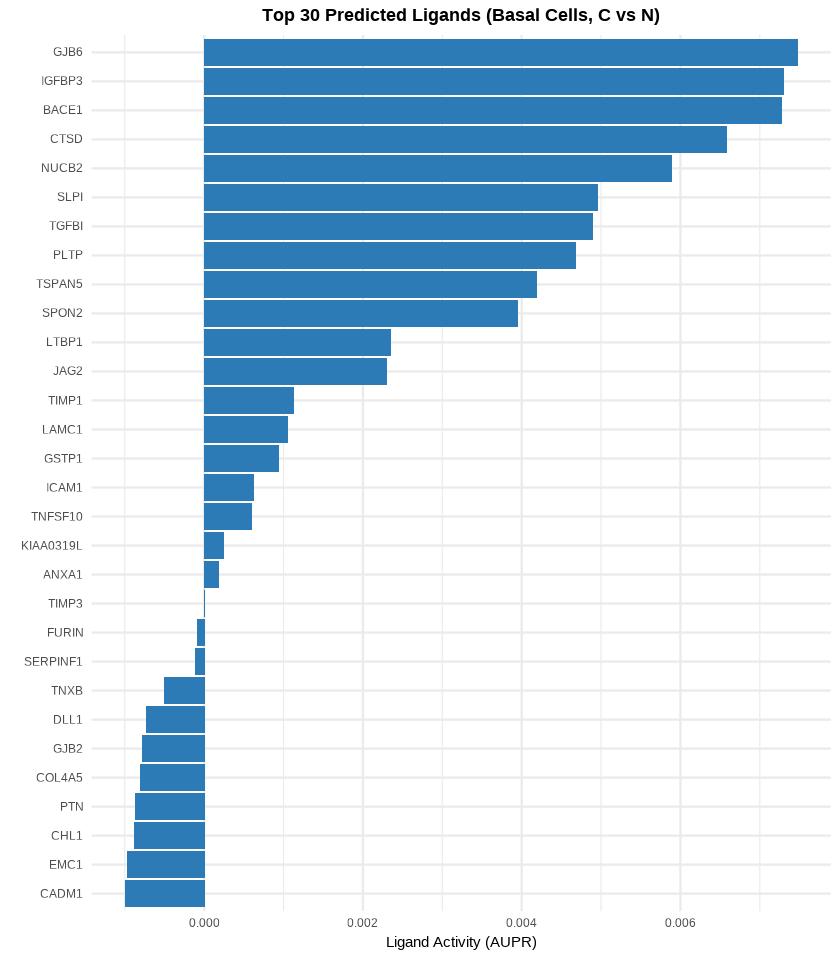

In [16]:
options(repr.plot.width = 7, repr.plot.height = 8)

best_ligands <- top_ligands(result)
activities <- ligand_activities(result)

top_act <- activities[activities$test_ligand %in% best_ligands, ]
top_act$test_ligand <- factor(top_act$test_ligand, levels = rev(best_ligands))

ggplot(top_act, aes(x = aupr_corrected, y = test_ligand)) +
    geom_col(fill = "#2C7BB6") +
    labs(x = "Ligand Activity (AUPR)", y = NULL,
         title = "Top 30 Predicted Ligands (Basal Cells, C vs N)") +
    theme_minimal() +
    theme(plot.title = element_text(hjust = 0.5, face = "bold"))

**Interpretation**: AUPR (area under precision-recall curve) measures how well a ligand's predicted targets overlap with the condition-specific DE genes in basal cells. Higher AUPR indicates the ligand is more likely driving the gene expression changes observed between contralateral and normal adjacent tissue.

### Ligand Activity Heatmap (nichenetr)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the nichenetr package.
  Please report the issue at <https://github.com/saeyslab/nichenetr/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the nichenetr package.
  Please report the issue at <https://github.com/saeyslab/nichenetr/issues>.”


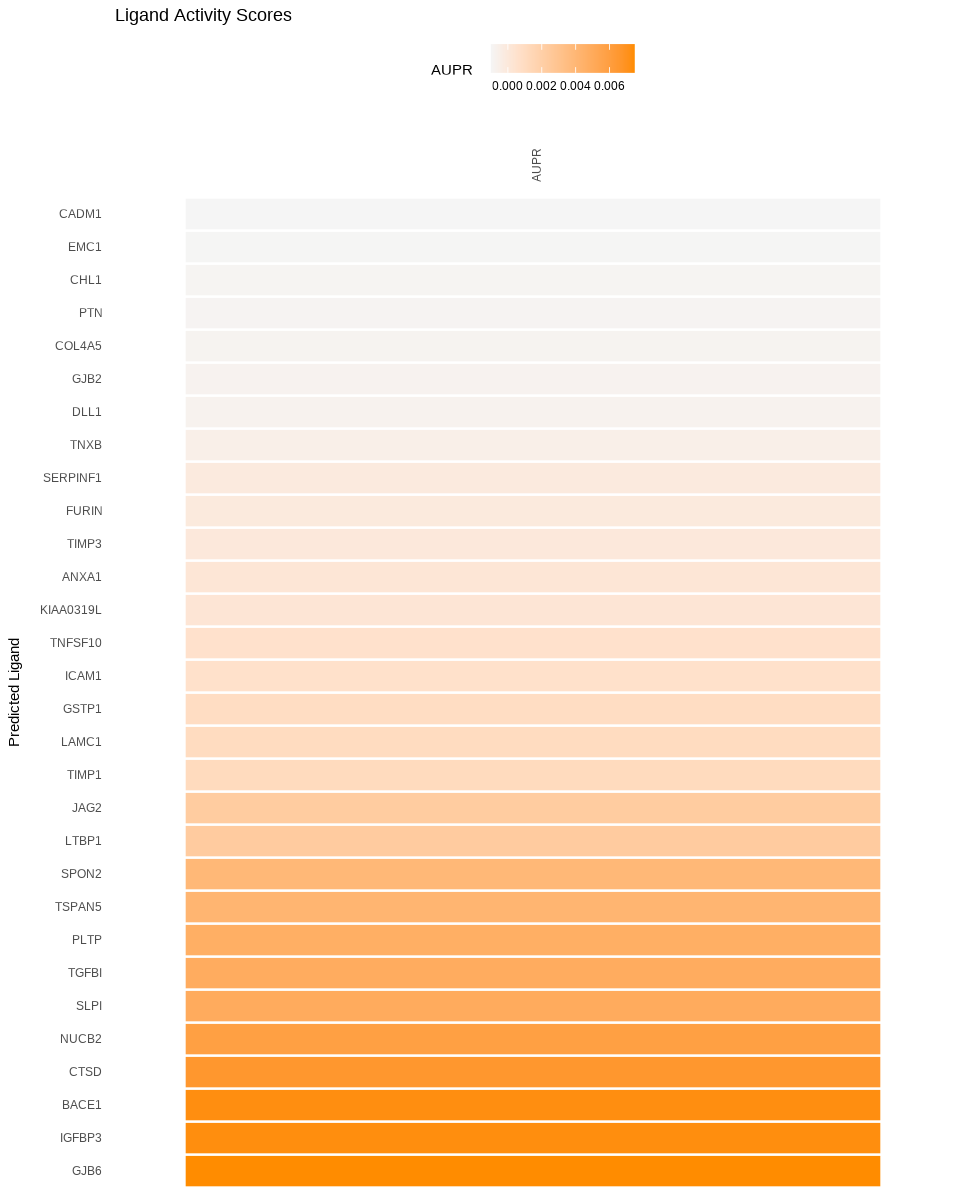

In [17]:
options(repr.plot.width = 8, repr.plot.height = 10)

activity_scores <- activities[activities$test_ligand %in% best_ligands, ]
activity_matrix <- as.matrix(activity_scores[, "aupr_corrected", drop = FALSE])
rownames(activity_matrix) <- activity_scores$test_ligand
colnames(activity_matrix) <- "AUPR"
activity_matrix <- activity_matrix[best_ligands, , drop = FALSE]

nichenetr::make_heatmap_ggplot(
    activity_matrix,
    y_name = "Predicted Ligand",
    x_name = "",
    legend_title = "AUPR",
    color = "darkorange"
) + ggtitle("Ligand Activity Scores")

### Ligand-Target Heatmap

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)

best_targets <- top_targets(result, n = 50)
ltm <- ligand_target_matrix(network)

target_rows <- intersect(best_targets, rownames(ltm))
ligand_cols <- intersect(best_ligands, colnames(ltm))
vis_matrix <- ltm[target_rows, ligand_cols, drop = FALSE]

nonzero <- vis_matrix[vis_matrix > 0]
if (length(nonzero) > 0) {
    vis_matrix[vis_matrix < quantile(nonzero, 0.33)] <- 0
}
vis_matrix <- vis_matrix[rowSums(vis_matrix) > 0, , drop = FALSE]

nichenetr::make_heatmap_ggplot(
    vis_matrix,
    y_name = "Target Gene",
    x_name = "Predicted Ligand",
    legend_title = "Regulatory\nPotential",
    color = "purple"
)

**Interpretation**: This heatmap shows the regulatory potential between top ligands (columns) and their predicted target genes (rows) from the context-specific ligand-target matrix. Entries below the 33rd percentile are set to zero for visual clarity. Ligands with many non-zero entries regulate a broad set of targets; sparse columns indicate more specific regulatory effects.

### Sankey Visualization with ccflowR

The bar plot identifies candidate ligands, and the ligand-target heatmap identifies receiver genes supporting them. ccflowR answers the path-level question: **which sender -> ligand -> receptor -> target -> basal receiver routes explain the strongest C-vs-N basal-cell communication hypotheses?**

`prepare_for_ccflowr()` converts the `ContextResult` into path rows with sender, ligand, receptor, receiver, and score columns. `combine_sankey_data()` rescales and thresholds those rows so the graph emphasizes the most interpretable paths.

Interpretation rules:

- Wider flows are higher-priority paths after ContextNet scoring and global scaling.
- The sender node means the ligand is plausible from that cell population, not that contact has been proven.
- The receptor and target portions of the path are the mechanistic hypotheses to inspect in expression, perturbation, or spatial data.
- Use `threshold_quantile` as a visualization control: higher values show fewer, stronger paths; lower values show more hypotheses.


In [ ]:
sankey_raw <- prepare_for_ccflowr(
    result,
    expression_data = seurat_cn,
    network = network,
    group_col = GROUP_COL,
    top_n_ligands = 50,
    min_cells = MIN_CELLS
)

sankey_data <- combine_sankey_data(sankey_raw, threshold_quantile = 0.95)

cat("Raw ccflowR path rows:", nrow(sankey_raw), "
")
cat("Rows after thresholding:", nrow(sankey_data), "
")
head(sankey_data)


In [ ]:
if (requireNamespace("ccflowR", quietly = TRUE)) {
    cell_types_in_plot <- unique(c(sankey_data$sender, sankey_data$receiver))
    palette <- grDevices::hcl.colors(length(cell_types_in_plot), palette = "Dark 3")
    cell_colors <- stats::setNames(palette, cell_types_in_plot)
    ccflowR::sankey_flow(sankey_data, cell_colors)
} else {
    message("ccflowR is not installed. Install it to render the Sankey graph: remotes::install_github('settylab/ccflowR')")
}


## Step 7: Export

### Save and Load Results

In [ ]:
tmp_dir <- tempdir()

# Save
save_contextnet(result, file.path(tmp_dir, "analysis.cnet"))

# Peek at saved file without loading
peek_contextnet(file.path(tmp_dir, "analysis.cnet"))

In [ ]:
# Reload later
result_loaded <- load_contextnet(file.path(tmp_dir, "analysis.cnet"))
top_ligands(result_loaded)

### Export Tables

In [ ]:
write.csv(ligand_activities(result), file.path(tmp_dir, "ligand_activities.csv"), row.names = FALSE)
write.csv(ligand_target_links(result), file.path(tmp_dir, "ligand_target_links.csv"), row.names = FALSE)

cat("Exported to:", tmp_dir, "\n")
list.files(tmp_dir, pattern = "\\.(cnet|csv)$")

In [ ]:
sessionInfo()

## Key Parameters

| Parameter | Required | Description |
|-----------|----------|-------------|
| `sender` | Yes | Sender cell type(s) expressing ligands |
| `receiver` | Yes | Receiver cell type |
| `ident_col` | Yes* | Metadata column for DE grouping |
| `ident_1` | Yes* | Value(s) for group 1 (upregulated genes); can be a vector |
| `ident_2` | Yes* | Value(s) for group 2 (reference); can be a vector |
| `de_subset_receiver` | No | `TRUE` (default): DE within receiver cells. `FALSE`: DE across all cells |
| `group_col` | No | Metadata column with cell type labels (default: `"cell_type"`) |
| `geneset_oi` | No | Custom gene set; auto-computed from DE if NULL |
| `top_n_ligands` | No | Number of top ligands (default: 30) |
| `nichenet_database` | No | Path to NicheNet data files |

*Required unless `geneset_oi` is provided directly.

## Using the Context-Specific Matrix with nichenetr Directly

ContextNet's reusable output from the integration step is the **context-specific ligand-target matrix**. If you want more control over the analysis, extract the matrix and use it in nichenetr's own functions:

```r
ltm <- ligand_target_matrix(network)

ligand_activities <- nichenetr::predict_ligand_activities(
    geneset = geneset_oi,
    background_expressed_genes = background_genes,
    ligand_target_matrix = ltm,
    potential_ligands = potential_ligands
)
```

This is useful when you already have custom DE results, want to test a curated gene set, need additional filtering, or want to compare the ContextNet matrix against the original NicheNet matrix.

For complete examples, see the nichenetr tutorials:
- [Step-by-step analysis](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_steps.md) - full walkthrough of NicheNet with Seurat
- [Seurat wrapper](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_wrapper.md) - simplified one-function interface
- [Circos visualization](https://github.com/saeyslab/nichenetr/blob/master/vignettes/seurat_wrapper_circos.md) - circos plots for ligand-receptor-target links
- [Ligand activity on custom gene set](https://github.com/saeyslab/nichenetr/blob/master/vignettes/ligand_activity_geneset.md) - use your own gene set